# Histograms with segmentation
Necessary imports

In [ ]:
import cv2
import matplotlib.pyplot as plt
import pickle
from dataclasses import dataclass
from pathlib import Path

import numpy as np

## Image and ground truth loading
Code snippet from week1 code so it stays with a persistent method

In [ ]:
@dataclass(frozen=True)
class ImageDataset:
    """Image paths paired with integer IDs in deterministic filename order."""

    paths: tuple[Path, ...]
    ids: np.ndarray

    def __len__(self) -> int:
        return len(self.paths)


def image_id(path: Path) -> int:
    """Parse IDs from both `00012.jpg` and `bbdd_00012.jpg`."""
    return int(path.stem.rsplit("_", 1)[-1])


def load_image_dataset(directory: str | Path) -> ImageDataset:
    directory = Path(directory)
    # Sorting is essential: submission row i must correspond to query image i.
    paths = tuple(sorted(directory.glob("*.jpg")))
    if not paths:
        raise FileNotFoundError(f"No JPG images found in {directory}")
    ids = np.asarray([image_id(path) for path in paths], dtype=int)
    if len(np.unique(ids)) != len(ids):
        raise ValueError(f"Duplicate image IDs found in {directory}")
    return ImageDataset(paths=paths, ids=ids)


def load_ground_truth(path: str | Path) -> list[list[int]]:
    with Path(path).open("rb") as stream:
        values = pickle.load(stream)
    return [[int(image_id) for image_id in relevant] for relevant in values]


In [ ]:
train_dataset = load_image_dataset("../data/BBDD")
ground_truth = load_ground_truth("../data/qsd1_w1/gt_corresps.pkl")

## Simple image segmentation and histogramization

Simple pyramid segmentation which splits an (HxW) image onto NxN blocks of size (W/N, H/N). Histograms are computed on normalized lab space as in the last week code and normalized before being concatenated onto a 1D $b*N^2*3$ size vector (b being the bin size)

In [ ]:
def simple_segment_and_histogram(img, level, bins=48, plot=False, normalize=True, weights=None):
    
    """
    Segment a BGR image into a level x level grid and compute
    concatenated L, A, B histograms for every block.

    Returns
    -------
    np.ndarray
        Flattened array of length level * level * 3 * bins
        (reshape to (level * level, 3 * bins) to get one row per block).
    """

    h, w = img.shape[:2]
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)

    histograms = np.empty((level * level, 3 * bins), dtype=np.float32)

    y_edges = np.linspace(0, h, level + 1, dtype=int)
    x_edges = np.linspace(0, w, level + 1, dtype=int)

    for i in range(level):
        for j in range(level):
            idx = i * level + j
            block = lab[y_edges[i]:y_edges[i + 1],
                        x_edges[j]:x_edges[j + 1]]

            channel_histograms = []
            for channel in range(3):
                hist = cv2.calcHist([block], [channel], None,
                                    [bins], [0, 256]).ravel()
                if normalize:
                    hist /= max(hist.sum(), 1e-12)
                channel_histograms.append(hist)

            histograms[idx] = np.concatenate(channel_histograms)

    if plot:
        fig = plt.figure(figsize=(4 * (level + 1), 2.8 * level),
                         layout="constrained")
        outer = fig.add_gridspec(1, 2, width_ratios=[1, level])

        # ---- Left: image with the segmentation grid ----
        ax_img = fig.add_subplot(outer[0])
        ax_img.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

        # Block boundaries sit between pixels, hence the -0.5 offset.
        for x in x_edges[1:-1]:
            ax_img.axvline(x - 0.5, color="red", linewidth=1.5)
        for y in y_edges[1:-1]:
            ax_img.axhline(y - 0.5, color="red", linewidth=1.5)

        # Label each block at its center.
        for i in range(level):
            for j in range(level):
                cx = (x_edges[j] + x_edges[j + 1]) / 2
                cy = (y_edges[i] + y_edges[i + 1]) / 2
                ax_img.text(cx, cy, f"({i},{j})", color="white",
                            ha="center", va="center", fontsize=9,
                            bbox=dict(facecolor="black", alpha=0.5,
                                      edgecolor="none", pad=1.5))

        ax_img.set_title(f"Segmentation ({level}x{level} blocks)")
        ax_img.axis("off")

        # ---- Right: one histogram plot per block ----
        inner = outer[1].subgridspec(level, level)
        channel_names = ["L", "a", "b"]
        channel_colors = ["black", "green", "blue"]

        for i in range(level):
            for j in range(level):
                idx = i * level + j
                ax = fig.add_subplot(inner[i, j])

                for c, (name, color) in enumerate(
                        zip(channel_names, channel_colors)):
                    start, end = c * bins, (c + 1) * bins
                    ax.plot(np.arange(start, end),
                            histograms[idx, start:end],
                            color=color, linewidth=1.3, label=name)

                ax.axvline(bins - 0.5, color="gray",
                           linestyle="--", linewidth=0.8)
                ax.axvline(2 * bins - 0.5, color="gray",
                           linestyle="--", linewidth=0.8)

                ax.set_title(f"Block ({i}, {j})", fontsize=10)
                ax.set_xlim(0, 3 * bins - 1)
                ax.set_xticks([bins / 2 - 0.5,
                               1.5 * bins - 0.5,
                               2.5 * bins - 0.5])
                ax.set_xticklabels(channel_names)
                ax.grid(alpha=0.2)

                if j == 0:
                    ax.set_ylabel("Frequency" if normalize
                                  else "Pixel count")
                if i == 0 and j == level - 1:
                    ax.legend(fontsize=8, loc="upper right")

        plt.show()

    return histograms.flatten()

## Tests on images
To ensure that the image segmentation and histogramisation is going correctly, some tests and plotting are done on arbitrary images

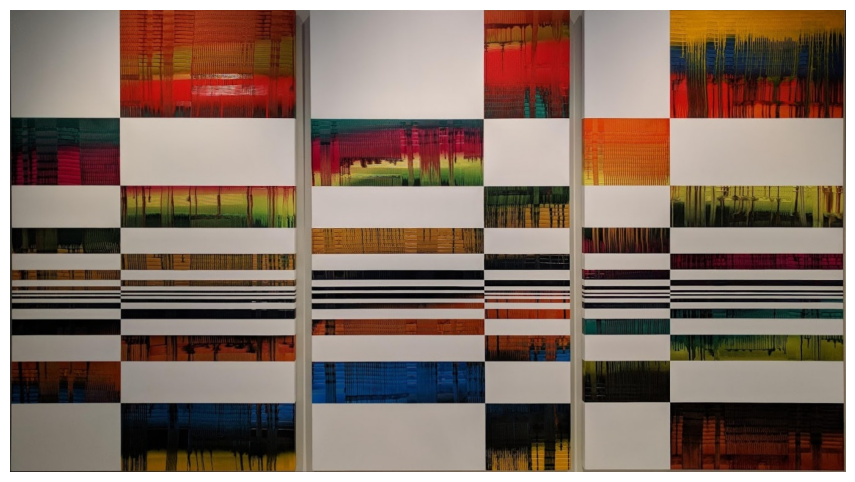

In [44]:
image = cv2.imread(train_dataset.paths[0].as_posix())
plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


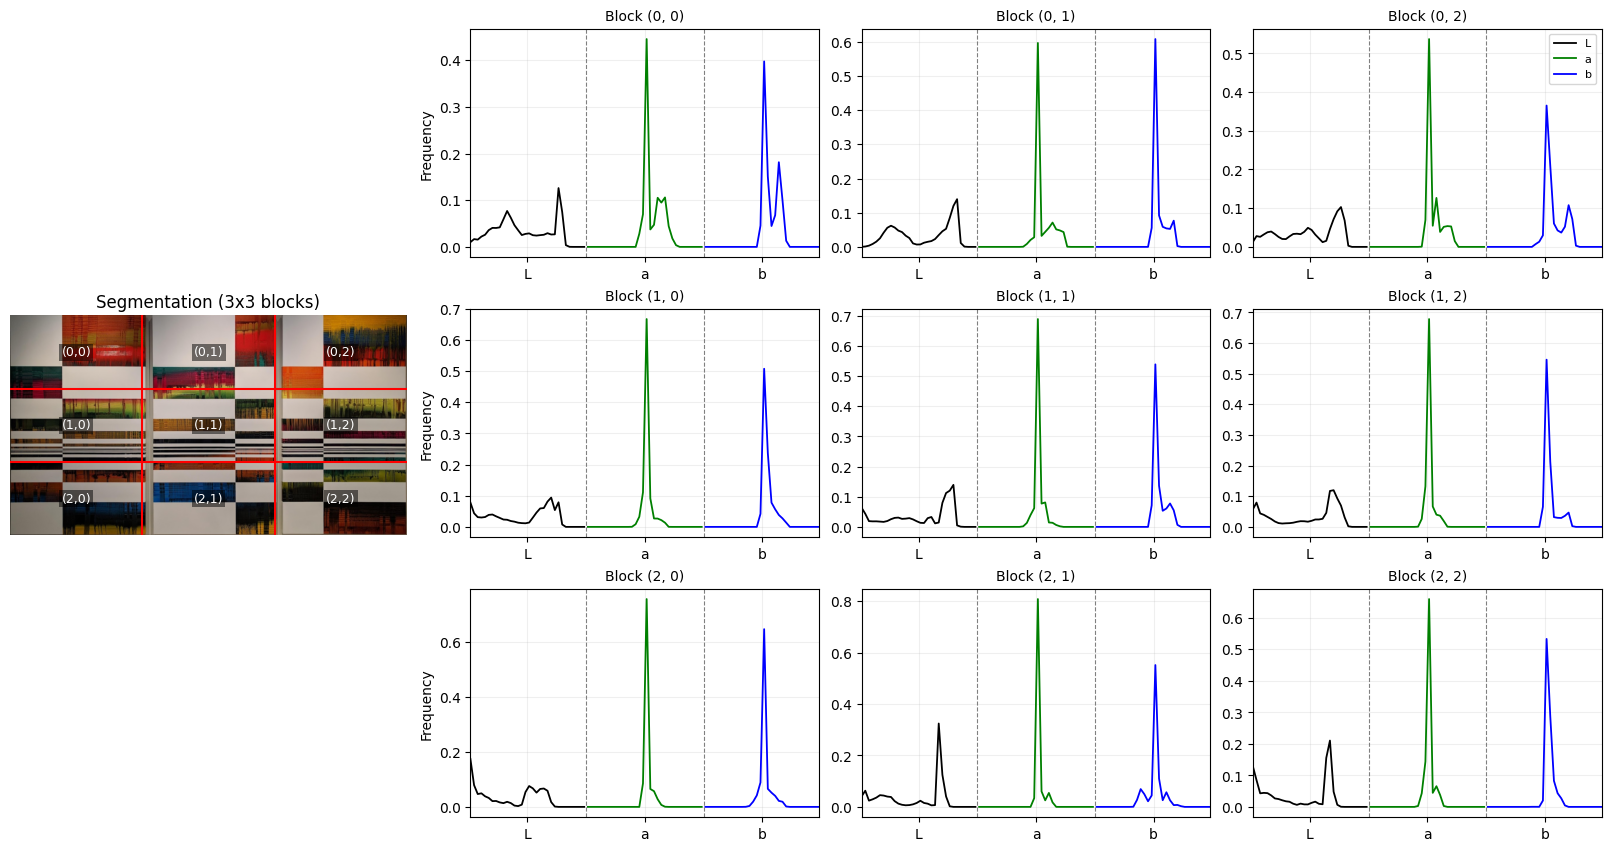

In [45]:
test_hist = simple_segment_and_histogram(image, level=3, plot=True)

In [46]:
test_hist.shape

(864,)